$Kx(t) = \int_0^\pi x(s) k(t,s) \, ds$

with $k(t,s) = \frac{2}{\pi} \sum_{n\geq 1}e^{-n^2T}\sin(ns)\sin(nt)$

symmetric with $\mu_i = e^{-i^2T}$
$\Rightarrow \|K\|_2 = \mu_1$

In [24]:
import numpy as np
from scipy.fft import dst, idst
from matplotlib import pyplot as plt


def heat_forward(x, T):
    """Apply K on the midpoint grid s_i = (i-1/2)*pi/n."""
    j = np.arange(1,len(x)+1)
    c = dst(x, type=2, norm='ortho') # sine coefficients
    return idst(np.exp(-T * j**2) * c, type=2, norm='ortho')


#Computing the timesteps
T = 0.01
n = 64
h = np.pi/n

#Initializing and constructing A
A = np.zeros((n,n))

for i in range(n):
    x = np.zeros(n)
    x[i] = 1
    A[:,i] = heat_forward(x, T)

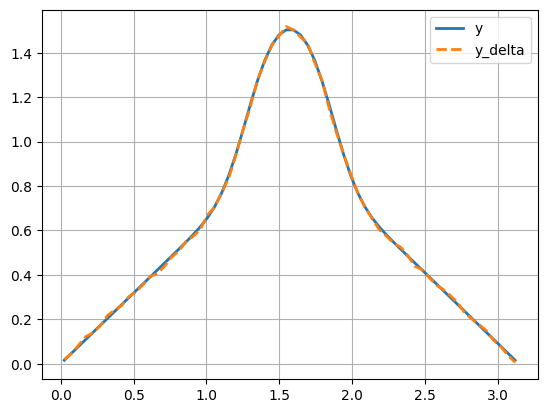

In [25]:
#Defining the function x(s) and applying the discrete operator to obtain y
s = (np.arange(1,n+1) - 1/2) *h

x = lambda s: np.minimum(s, np.pi - s) / (np.pi / 2) + 0.6 * (np.abs(s - np.pi / 2) < 0.3)
x_vec = np.zeros(n)
x_vec[:] = x(s)
Kx = heat_forward(x_vec, T)

#Adding noise to y
np.random.seed(42)
d = np.random.randn(n)
d = d / np.linalg.norm(d) * 0.01 * np.linalg.norm(Kx)
y_delta = Kx + d

plt.plot(s,Kx,label="y",lw=2)
plt.plot(s,y_delta,label="y_delta",linestyle="--",lw=2)
plt.legend()
plt.grid()
plt.show()


omega =  1.0202013400267558
The smallest relative Error is at ITERATION k=357
with RELATIVE ERROR 0.08128920767497971


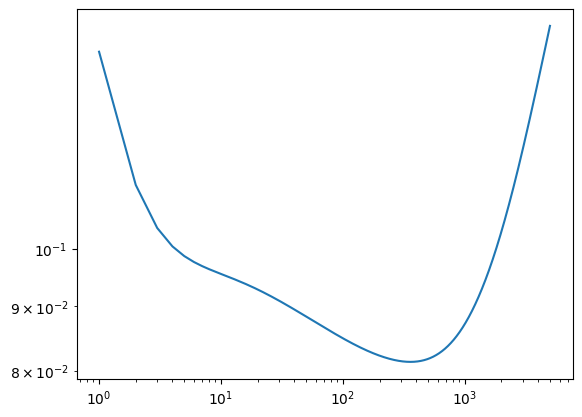

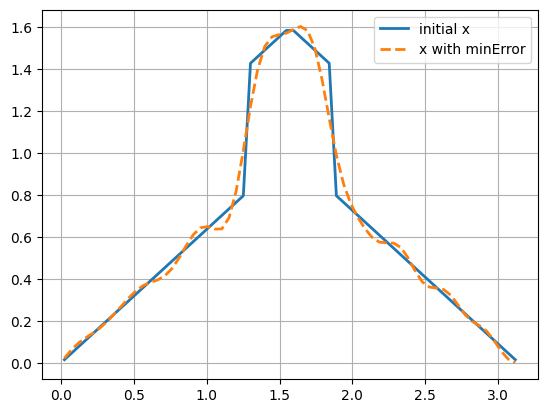

In [ ]:
# LANDWEBER ITERATION
A_norm2 = np.linalg.norm(A,ord=2)
omega = 1/ A_norm2 **2

# Two ways to calculate omega -> same result
print("omega = ",omega)
# print("norm k = ",1/np.exp(-T)**2)

k_top = 5000        #amount of iterations

relativeError = np.zeros(k_top)
x_k = np.zeros(n)
x_minError = np.zeros(n)
minError = 1000

for i in range(5000):   
    x_k = x_k + omega * A.T @ (y_delta - A@x_k)
    relativeError[i] = np.linalg.norm(x_k - x_vec)/np.linalg.norm(x_vec)

    if relativeError[i] < minError:
        minError_index = i
        minError = relativeError[i]
        x_minError = x_k

print(f"The smallest relative Error is at ITERATION k={minError_index}")
print(f"with RELATIVE ERROR {minError}")

plt.loglog(np.linspace(1,5000,5000),relativeError)
plt.show()

plt.plot(s,x_vec,label="initial x",lw=2)
plt.plot(s,x_minError,label="x with minError",lw=2,linestyle="--")
plt.legend()
plt.grid()
plt.show()

In [ ]:
#b) Experiment with the step-length
c_array = (0.25,0.5,1,1.5,1.9,2.05)

relativeError = np.zeros(k_top)
x_k = np.zeros(n)
x_minError = np.zeros(n)
minError = 1000

for c in c_array:
    omega = omega * c

    for i in range(5000):   
        x_k = x_k + omega * A.T @ (y_delta - A@x_k)
        relativeError[i] = np.linalg.norm(x_k - x_vec)/np.linalg.norm(x_vec)

        if relativeError[i] < minError:
            minError_index = i
            minError = relativeError[i]
            x_minError = x_k

print(f"For c={c}, \nthe smallest relative Error is at ITERATION k={minError_index}")
print(f"with RELATIVE ERROR {minError}")

plt.loglog(np.linspace(1,5000,5000),relativeError)
plt.show()

plt.plot(s,x_vec,label="initial x",lw=2)
plt.plot(s,x_minError,label="x with minError",lw=2,linestyle="--")
plt.legend()
plt.grid()
plt.show()
    

SyntaxError: invalid syntax (1710960892.py, line 2)